In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Fixer une graine aléatoire pour la reproductibilité
np.random.seed(42)

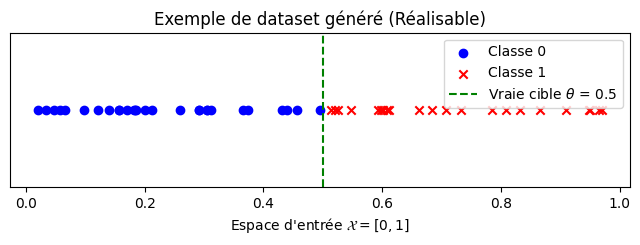

In [2]:
class ThresholdClassifier:
    def __init__(self, theta):
        self.theta = theta

    def predict(self, X):
        # f_theta(x) = 1 si x > theta, 0 sinon
        return (X > self.theta).astype(int)

def generate_data(m, theta, noise_rate=0.0, agnostic=False):
    # Échantillons x tirés uniformément de [0, 1]
    X = np.random.uniform(0, 1, m)

    # Étiquettes parfaites selon la fonction cible
    y = (X > theta).astype(int)

    if agnostic and noise_rate > 0.0:
        # Introduire du bruit en inversant aléatoirement les étiquettes avec la probabilité noise_rate
        flip_mask = np.random.rand(m) < noise_rate
        y[flip_mask] = 1 - y[flip_mask]

    return X, y

# Exemple de visualisation (Tâche 1)
theta_true = 0.5
X_sample, y_sample = generate_data(m=50, theta=theta_true)

plt.figure(figsize=(8, 2))
plt.scatter(X_sample[y_sample == 0], np.zeros_like(X_sample[y_sample == 0]), color='blue', label='Classe 0', marker='o')
plt.scatter(X_sample[y_sample == 1], np.zeros_like(X_sample[y_sample == 1]), color='red', label='Classe 1', marker='x')
plt.axvline(x=theta_true, color='green', linestyle='--', label=f'Vraie cible $\\theta$ = {theta_true}')
plt.yticks([])
plt.xlabel('Espace d\'entrée $\\mathcal{X} = [0, 1]$')
plt.title('Exemple de dataset généré (Réalisable)')
plt.legend()
plt.show()

In [3]:
def train_erm(X, y):
    """
    Stratégie ERM pour les classifieurs par seuil :
    On trie les points d'entrée. Le seuil optimal peut être testé
    entre les points triés ou aux extrémités, car la classe d'hypothèses
    est finie/structurée par les données observées.
    """
    sorted_indices = np.argsort(X)
    X_sorted = X[sorted_indices]
    y_sorted = y[sorted_indices]

    best_theta = 0.0
    min_empirical_error = float('inf')

    # Tester des seuils situés entre chaque paire de points adjacents
    # ainsi qu'aux bords.
    candidate_thetas = [0.0] + [(X_sorted[i] + X_sorted[i+1]) / 2 for i in range(len(X_sorted) - 1)] + [1.0]

    for theta in candidate_thetas:
        clf = ThresholdClassifier(theta)
        preds = clf.predict(X)
        # Erreur empirique : proportion d'erreurs
        err = np.mean(preds != y)

        if err < min_empirical_error:
            min_empirical_error = err
            best_theta = theta

    return ThresholdClassifier(best_theta), min_empirical_error

Taille m =   5 | Estimation Pr(L(h) > epsilon) = 0.306
Taille m =  10 | Estimation Pr(L(h) > epsilon) = 0.128
Taille m =  20 | Estimation Pr(L(h) > epsilon) = 0.016
Taille m =  50 | Estimation Pr(L(h) > epsilon) = 0.000
Taille m = 100 | Estimation Pr(L(h) > epsilon) = 0.000
Taille m = 200 | Estimation Pr(L(h) > epsilon) = 0.000


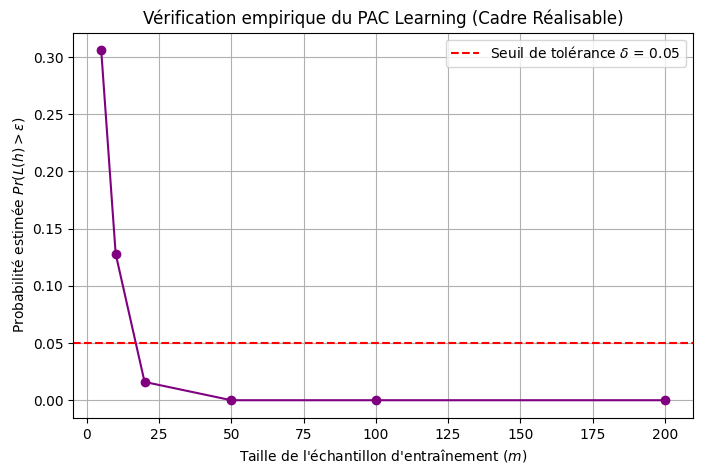

In [4]:
# Paramètres de l'expérience
theta_true = 0.4
sample_sizes = [5, 10, 20, 50, 100, 200]
n_repetitions = 500
epsilon = 0.1
delta = 0.05

# Génération d'un grand ensemble de test indépendant pour estimer la vraie erreur
X_test = np.random.uniform(0, 1, 10000)
y_test = (X_test > theta_true).astype(int)

probabilities_exceeded = []

for m in sample_sizes:
    exceeded_count = 0
    for _ in range(n_repetitions):
        X_train, y_train = generate_data(m, theta_true, agnostic=False)
        clf, emp_err = train_erm(X_train, y_train)

        # Calcul de la vraie erreur sur l'ensemble de test
        y_pred_test = clf.predict(X_test)
        true_err = np.mean(y_pred_test != y_test)

        if true_err > epsilon:
            exceeded_count += 1

    prob = exceeded_count / n_repetitions
    probabilities_exceeded.append(prob)
    print(f"Taille m = {m:3d} | Estimation Pr(L(h) > epsilon) = {prob:.3f}")

# Visualisation de l'évolution de la probabilité
plt.figure(figsize=(8, 5))
plt.plot(sample_sizes, probabilities_exceeded, marker='o', linestyle='-', color='purple')
plt.axhline(y=delta, color='red', linestyle='--', label=f'Seuil de tolérance $\\delta$ = {delta}')
plt.xlabel('Taille de l\'échantillon d\'entraînement ($m$)')
plt.ylabel('Probabilité estimée $Pr(L(h) > \\epsilon)$')
plt.title('Vérification empirique du PAC Learning (Cadre Réalisable)')
plt.legend()
plt.grid(True)
plt.show()

In [5]:
noise_rate = 0.15 # Taux de bruit sur les étiquettes
agnostic_probabilities = []

print("--- Expérience Agnostique (avec bruit) ---")
for m in sample_sizes:
    exceeded_count = 0
    for _ in range(n_repetitions):
        X_train, y_train = generate_data(m, theta_true, noise_rate=noise_rate, agnostic=True)
        clf, emp_err = train_erm(X_train, y_train)

        # Vraie erreur évaluée par rapport à la distribution propre d'origine (sans bruit)
        y_pred_test = clf.predict(X_test)
        true_err = np.mean(y_pred_test != y_test)

        # Dans le cadre agnostique, on compare à la meilleure erreur possible augmentée de epsilon
        # (Pour simplifier, on suit l'évolution générale de l'erreur)
        if true_err > (epsilon + noise_rate / 2):
            exceeded_count += 1

    prob = exceeded_count / n_repetitions
    agnostic_probabilities.append(prob)
    print(f"Taille m = {m:3d} (Agnostique) | Probabilité d'erreur élevée = {prob:.3f}")

--- Expérience Agnostique (avec bruit) ---
Taille m =   5 (Agnostique) | Probabilité d'erreur élevée = 0.346
Taille m =  10 (Agnostique) | Probabilité d'erreur élevée = 0.208
Taille m =  20 (Agnostique) | Probabilité d'erreur élevée = 0.118
Taille m =  50 (Agnostique) | Probabilité d'erreur élevée = 0.016
Taille m = 100 (Agnostique) | Probabilité d'erreur élevée = 0.000
Taille m = 200 (Agnostique) | Probabilité d'erreur élevée = 0.000
